# MovieLens Recommender: experiment review

Rank unseen movies from historical user ratings and measure whether personalized collaborative filtering adds value over popular titles. The project implements regularized biased matrix factorization directly, then evaluates both rating error and full-catalog recommendation quality.

This notebook inspects the committed experiment. Run `python -m movie_recs train` from the repository root to regenerate the evidence. Raw datasets and local artifacts are not embedded here.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/metrics.json").is_file():
    root = root.parent
report = json.loads((root / "reports/metrics.json").read_text())
print("Selected model:", report["selected"])
print("Split:", report["split"])
print("Recorded Python:", report["provenance"]["python"])

Selected model: popularity
Split: {'train': 80003, 'validation': 9997, 'test': 10000, 'method': 'global timestamp 80/10/10; timestamp ties kept together'}
Recorded Python: 3.11.14


## Compare held-out performance

Lower MAE/RMSE/log loss is better; higher F1, accuracy, recall and NDCG is better. The selected model was chosen before examining test outcomes.

In [2]:
comparison = pd.DataFrame(report["test_ranking"]).T
display(comparison)

,recall_at_10,ndcg_at_10,evaluated_users,catalog_coverage_at_10
popularity,0.054960,0.116018,52.0,0.047030
factorization,0.087176,0.137412,52.0,0.102723


In [3]:
print("Warm rating rows:", report["warm_test_ratings"])
print("Excluded cold rating rows:", report["excluded_cold_test_ratings"])
display(pd.DataFrame(report["all_user_test_ranking"]).T)

Warm rating rows: 1344
Excluded cold rating rows: 8656


,recall_at_10,ndcg_at_10,evaluated_users,catalog_coverage_at_10
popularity,0.078977,0.226791,147.0,0.04703
factorization,0.090373,0.234358,147.0,0.10953


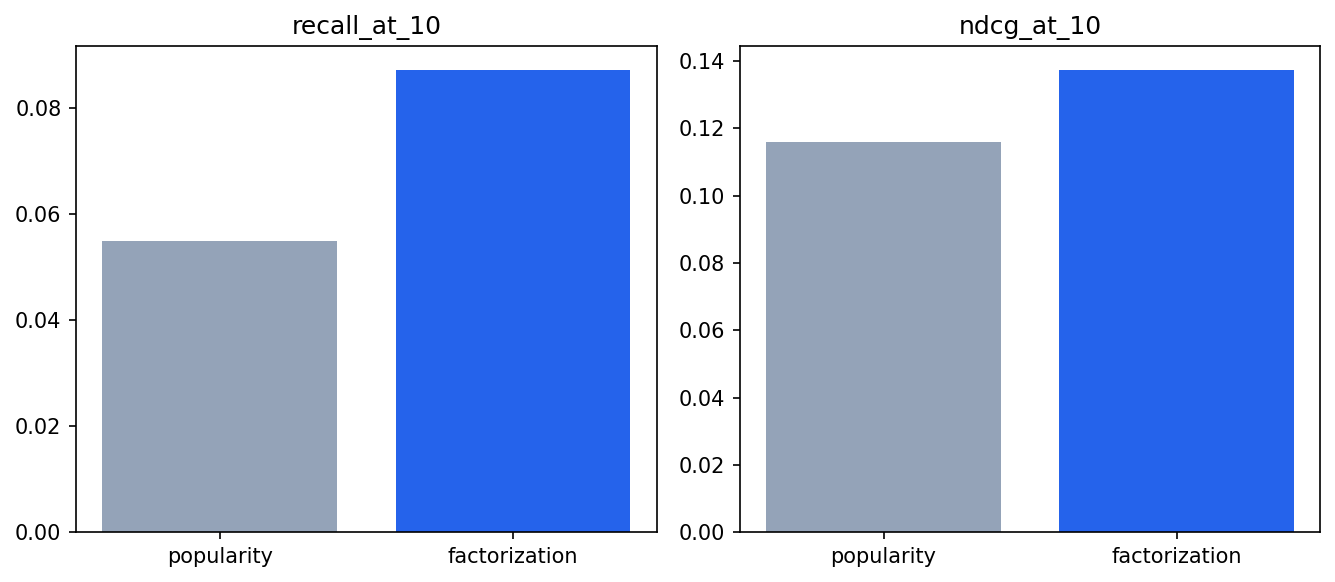

In [4]:
display(Image(filename=str(root / "reports/evaluation.png")))

## What the measurements mean

Popularity wins validation NDCG and remains the selected inference strategy, even though factorization has higher test NDCG on warm users. The global split produces substantial cold start: only 1,344 of 10,000 test ratings involve warm users and known items. Warm ranking covers 52 users; the additional all-user report covers 147 eligible users and uses popularity for unseen users. The optimizer hits its 100-iteration cap; the report explicitly records that it did not declare convergence.

## Where they stop

Historical explicit ratings have selection bias and do not represent randomized exposure. A missing rating is not a known dislike, and offline relevance does not establish user satisfaction. The small warm-user cohort makes ranking metrics noisy. New items are excluded because collaborative factors cannot score them reliably. There is no content model, online A/B test, or causal claim. Complexity is roughly O(iterations × ratings × factors) for training and O(catalog × factors) per warm-user ranking.